# code_128 · Beam PINN terms and automatic derivatives

**Book:** section 25.2. A self-contained scientific-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_25_GUIDE.md), [run evidence](../CHAPTER_25_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_128).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2928;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2928


<a id="beam-pinn-loss"></a>
 ## Every loss term has a separate origin and scale
 Learn normalized beam deflection v=24*EI*w/q on[0,1], so D4v=24, v(0)=v(1)=v''(0)=v''(1)=0 and generated truth v=x−2x³+x4. Six noisy interior v observations are source data. Thirty-two fixed interior collocation locations provide equation constraints; boundary terms separately penalize displacement and v''/12. Normalize equation residual as D4v/24−1. A two-hidden-layer, sixteen-unit tanh MLP receives 1,200 Adam updates at0.005 for each of three declared recipes: data-only, physics with boundary weight0.1, and physics with boundary weight10. Reset initialization for each. An independent 63-point development grid plus boundary defects selects among physics candidates using known equations only. A separate 401-point assessment grid supplies reference errors; no assessment quantity chooses weights/checkpoints.


,model,source_data_MSE,source_residual_MSE,boundary_loss,development_physics_score,final_field_MSE,final_residual_MSE,max_endpoint_displacement,parameters
0,Data only,0.000001,1.536756,1.307996e-03,1.534208,7.079952e-06,1.540212,0.010056,321
1,PINN bc0.1,0.000031,0.000142,2.253370e-03,0.002418,5.264272e-05,0.000189,0.023081,321
2,PINN bc10,0.000002,0.000052,8.032714e-08,0.000069,1.076188e-08,0.000086,0.000293,321


Development-selected: PINN bc10


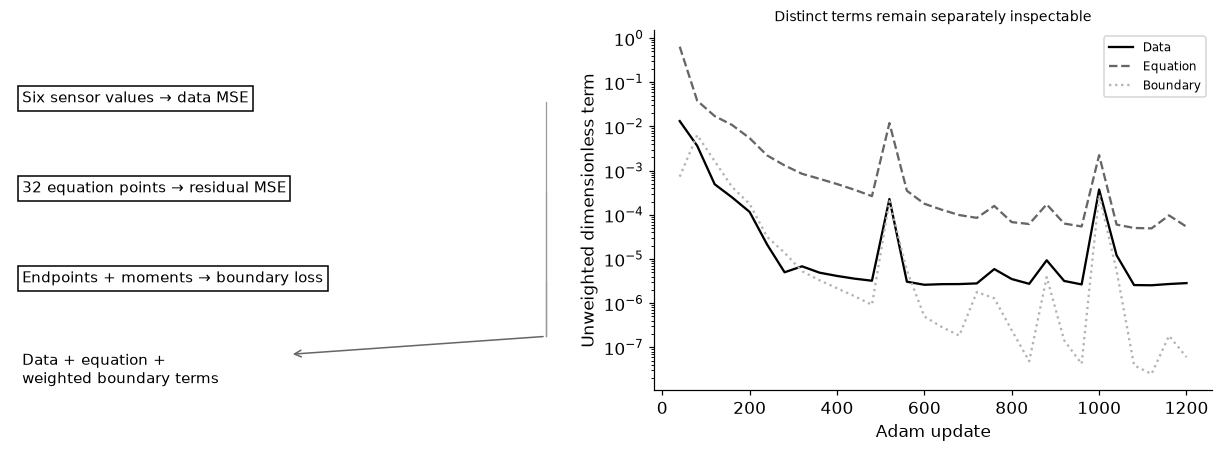

In [2]:
import copy
def truth(x):return x-2*x**3+x**4
def derivative(y,x,order=1):
    for j in range(order):y=torch.autograd.grad(y,x,torch.ones_like(y),create_graph=True)[0]
    return y
check=torch.linspace(.01,.99,17)[:,None].requires_grad_(True);torch.testing.assert_close(derivative(truth(check),check,4),torch.full_like(check,24),atol=1e-12,rtol=1e-12)
sensors=torch.tensor([.08,.22,.39,.61,.78,.92])[:,None];observations=truth(sensors)+torch.tensor(rng.normal(0,.002,(6,1)));collocation=torch.tensor(np.linspace(.015,.985,32))[:,None].requires_grad_(True);boundary=torch.tensor([[0.],[1.]],requires_grad=True);dev=torch.tensor((np.arange(63)+.5)/63)[:,None].requires_grad_(True);test=torch.tensor(np.linspace(0,1,401))[:,None].requires_grad_(True)
def model_factory():return nn.Sequential(nn.Linear(1,16),nn.Tanh(),nn.Linear(16,16),nn.Tanh(),nn.Linear(16,1))
def parts(model,points):
    residual=derivative(model(points),points,4)/24-1;bv=model(boundary);moment=derivative(bv,boundary,2)/12
    return ((model(sensors)-observations)**2).mean(),(residual**2).mean(),(bv**2).mean()+(moment**2).mean()
fitted={};rows=[];histories={};initial_gradients={}
for name,physics_weight,boundary_weight in [('Data only',0.,0.),('PINN bc0.1',1.,.1),('PINN bc10',1.,10.)]:
    torch.manual_seed(SEED);model=model_factory();optimizer=torch.optim.Adam(model.parameters(),lr=.005);history=[];terms=parts(model,collocation);gn=[]
    for term in terms:
        grads=torch.autograd.grad(term,tuple(model.parameters()),retain_graph=True,allow_unused=True);gn.append(float(torch.sqrt(sum((g*g).sum() for g in grads if g is not None))))
    initial_gradients[name]=gn
    for step in range(1,1201):
        optimizer.zero_grad();data_loss,residual_loss,bc_loss=parts(model,collocation);loss=data_loss+physics_weight*residual_loss+boundary_weight*bc_loss;loss.backward();optimizer.step()
        if step%40==0:history.append([step,float(data_loss.detach()),float(residual_loss.detach()),float(bc_loss.detach())])
    data_loss,residual_loss,bc_loss=parts(model,collocation);dev_loss=parts(model,dev)[1]+parts(model,dev)[2];pred=model(test);test_residual=derivative(pred,test,4)/24-1
    rows.append({'model':name,'source_data_MSE':float(data_loss.detach()),'source_residual_MSE':float(residual_loss.detach()),'boundary_loss':float(bc_loss.detach()),'development_physics_score':float(dev_loss.detach()),'final_field_MSE':float(((pred-truth(test))**2).mean().detach()),'final_residual_MSE':float((test_residual**2).mean().detach()),'max_endpoint_displacement':float(torch.max(torch.abs(model(boundary))).detach()),'parameters':sum(p.numel() for p in model.parameters())});fitted[name]=model;histories[name]=history
selected=min([r for r in rows if r['model']!='Data only'],key=lambda r:r['development_physics_score'])['model'];assert len(rows)==3 and all(np.isfinite(r['final_field_MSE']) for r in rows)
RESULTS.update(comparisons=rows,selected_physics_candidate=selected,initial_unweighted_gradient_norms=initial_gradients,source_sensors=6,source_collocation=32,development_points=63,final_points=401,updates_per_candidate=1200,learning_rate=.005);display(pd.DataFrame(rows));print('Development-selected:',selected)
fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].axis('off')
for y,label in [(.8,'Six sensor values → data MSE'),(.55,'32 equation points → residual MSE'),(.3,'Endpoints + moments → boundary loss')]:axes[0].text(.02,y,label,fontsize=10,bbox=dict(fc='white',boxstyle='square'))

for y in [.8,.55,.3]:axes[0].plot([.96,.96],[y,.15],color='.6',linewidth=.8)
axes[0].annotate('',xy=(.5,.1),xytext=(.96,.15),arrowprops=dict(arrowstyle='->',color='.4'))
axes[0].text(.02,.02,'Data + equation +\nweighted boundary terms',fontsize=10);axes[0].set(xlim=(0,1),ylim=(0,1))
for k,label in enumerate(['Data','Equation','Boundary']):axes[1].semilogy(np.array(histories[selected])[:,0],np.maximum(np.array(histories[selected])[:,k+1],1e-14),label=label,color=['black','.4','.7'][k],linestyle=['-','--',':'][k])
axes[1].set(xlabel='Adam update',ylabel='Unweighted dimensionless term',title='Distinct terms remain separately inspectable');axes[1].legend(fontsize=8);plt.show()


<a id="off-grid-physics-check"></a>
 ## Differentiate the represented function, then check what it solves
 Autograd matches the known fourth derivative of the analytic polynomial before fitting. It differentiates the network calculation, not the unknown physical truth. Every candidate retains its own data, residual and boundary errors. The selection criterion has no dense reference displacement; it uses an independent grid of known equation constraints and endpoint conditions. Source observations are noisy while governing physics is exact by construction. In a real discrepancy problem these terms can conflict for substantive reasons. A fourth-order equation needs the stated four boundary conditions. The data-only model's residual is evaluated diagnostically even though it does not optimize it. Tanh is smooth enough for fourth derivatives; ReLU's almost-everywhere higher derivatives would be inappropriate here.


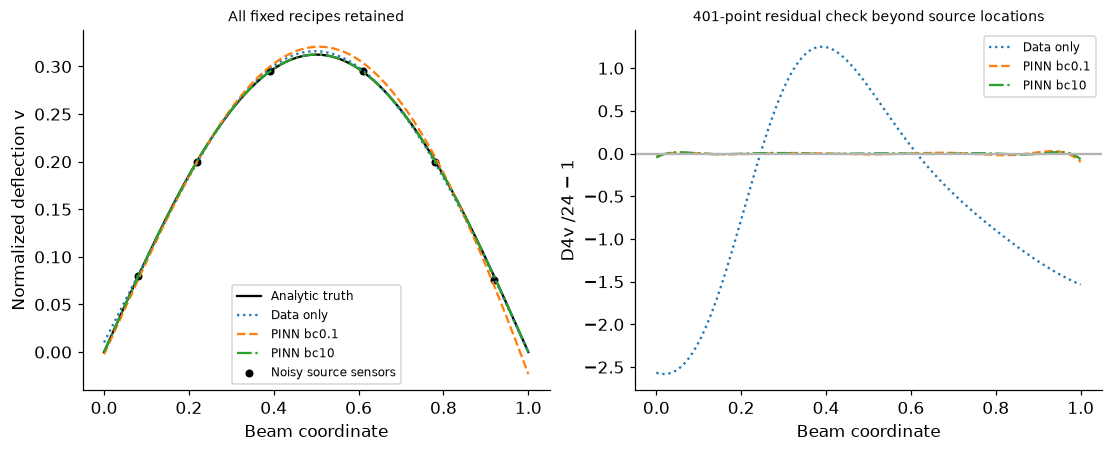

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=test.detach().numpy().ravel();axes[0].plot(xx,truth(test).detach().numpy().ravel(),'k-',label='Analytic truth')
for name,style in zip(fitted,[':','--','-.']):
    m=fitted[name];p=m(test);rr=derivative(p,test,4)/24-1;axes[0].plot(xx,p.detach().numpy().ravel(),style,label=name);axes[1].plot(xx,rr.detach().numpy().ravel(),style,label=name)
axes[0].scatter(sensors.numpy(),observations.numpy(),color='black',s=18,label='Noisy source sensors');axes[0].set(xlabel='Beam coordinate',ylabel='Normalized deflection v',title='All fixed recipes retained');axes[0].legend(fontsize=8);axes[1].axhline(0,color='.7');axes[1].set(xlabel='Beam coordinate',ylabel="D4v /24 − 1",title='401-point residual check beyond source locations');axes[1].legend(fontsize=8);plt.show()
assert collocation.shape[0]==32 and test.shape[0]==401


In [4]:
summary={'example_id':'code_128','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual fourth-order autograd beam residual', 'separate data equation and boundary terms', 'dimensionless residual scaling', 'fixed weight candidates and independent development grid', 'dense off-collocation validation'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual fourth-order autograd beam residual", "separate data equation and boundary terms", "dimensionless residual scaling", "fixed weight candidates and independent development grid", "dense off-collocation validation"], "elapsed_seconds": 4.432, "example_id": "code_128", "hardware": "Darwin arm64 CPU", "results": {"comparisons": [{"boundary_loss": 0.0013079959647814038, "development_physics_score": 1.5342083632478019, "final_field_MSE": 7.079952083180492e-06, "final_residual_MSE": 1.5402122396837004, "max_endpoint_displacement": 0.010055870921343982, "model": "Data only", "parameters": 321, "source_data_MSE": 1.0354372617205227e-06, "source_residual_MSE": 1.5367555367758068}, {"boundary_loss": 0.002253369773889315, "development_physics_score": 0.0024181760822685346, "final_field_MSE": 5.264272284195708e-05, "final_residual_MSE": 0.00018897398197830658, "max_endpoint_displacement": 0.023081315594603323, "model": "PINN bc0.1", "paramete